# Regularization: Linear vs Ridge vs Lasso

Two experiments: (1) the effect of 5 extreme outliers on linear, Ridge and Lasso fits; (2) a sparse problem with 100 features and only 10 informative ones, where Lasso's feature selection is compared with linear regression and Ridge.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import explained_variance_score, mean_absolute_error, mean_squared_error, r2_score

In [3]:
def regression_results(y_true, y_pred, regr_type):

    # Regression metrics
    ev = explained_variance_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred) 
    mse = mean_squared_error(y_true, y_pred) 
    r2 = r2_score(y_true, y_pred)
    
    print('Evaluation metrics for ' + regr_type + ' Linear Regression')
    print('explained_variance: ',  round(ev,4)) 
    print('r2: ', round(r2,4))
    print('MAE: ', round(mae,4))
    print('MSE: ', round(mse,4))
    print('RMSE: ', round(np.sqrt(mse),4))
    print()


In [4]:
# Generate synthetic data
noise=1
np.random.seed(42)
X = 2 * np.random.rand(1000, 1)
y = 4 + 3 * X + noise*np.random.randn(1000, 1)  # Linear relationship with some noise
y_ideal =  4 + 3 * X
# Specify the portion of the dataset to add outliers (e.g., the last 20%)
y_outlier = pd.Series(y.reshape(-1).copy())

# Identify indices where the feature variable X is greater than a certain threshold
threshold = 1.5  # Example threshold to add outliers for larger feature values
outlier_indices = np.where(X.flatten() > threshold)[0]

# Add outliers at random locations within the specified portion
num_outliers = 5  # Number of outliers to add
selected_indices = np.random.choice(outlier_indices, num_outliers, replace=False)

# Modify the target values at these indices to create outliers (add significant noise)
y_outlier[selected_indices] += np.random.uniform(50, 100, num_outliers)

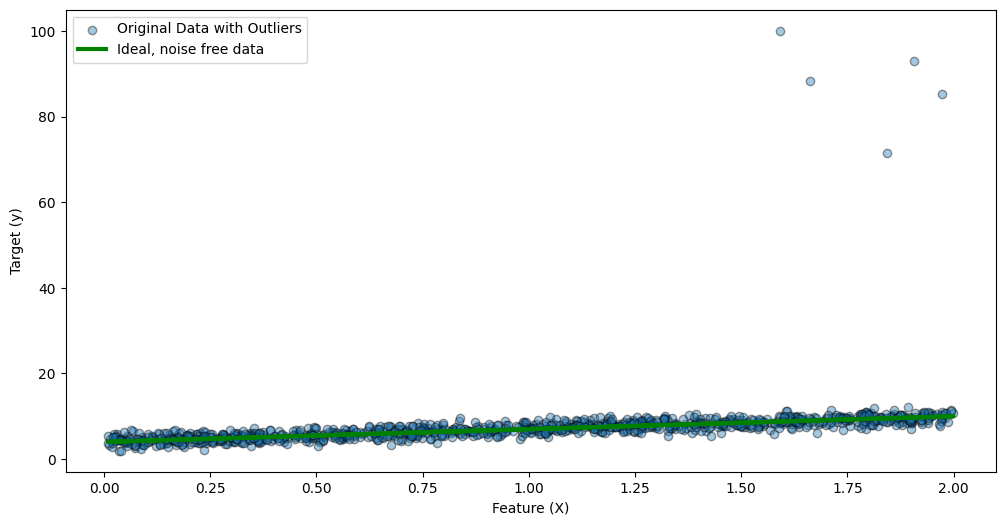

In [5]:
plt.figure(figsize=(12, 6))

# Scatter plot of the original data with outliers
plt.scatter(X, y_outlier, alpha=0.4,ec='k', label='Original Data with Outliers')
plt.plot(X, y_ideal,  linewidth=3, color='g',label='Ideal, noise free data')

plt.xlabel('Feature (X)')
plt.ylabel('Target (y)')
plt.title('')
plt.legend()
plt.show()

Almost all the data follows a clean linear trend, but 5 extreme outliers sit far above it, all on the right side, which is the worst place for a linear model.

The real relationship is simple and linear. The green line rises from about y ≈ 4 at X = 0 to about y ≈ 10 at X = 2, a slope of about 3 (consistent with y = 4 + 3X). The normal points scatter tightly around it, within about ±2.
The 5 outliers are huge compared with the data. They have y ≈ 71 to 100, roughly 8 to 10 times the normal values (8–12) at those X positions. They're only about 0.5% of the points (5 of about 1,000), but they are extreme.
They're all at high X (between 1.6 and 2.0). That's what makes them dangerous. A point far from the centre of X has high leverage: it can tilt the regression line a lot. Since all 5 pull upward at the right end, they will increase the fitted slope.
Squared error magnifies them. Ordinary least squares minimizes the sum of squared errors. An outlier about 85 units off contributes about 7,000 to that sum, while a normal point contributes about 1–4. So 5 points can outweigh the other 995.

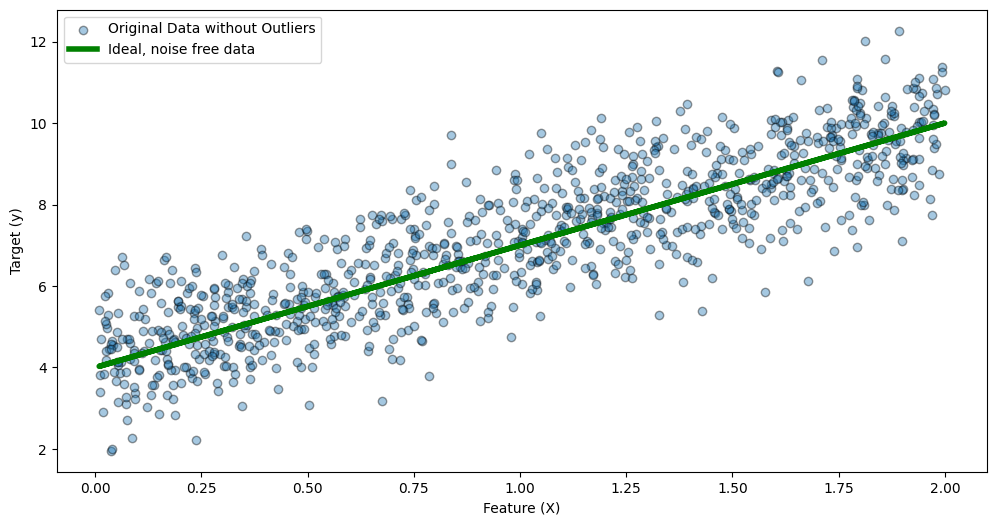

In [7]:
plt.figure(figsize=(12, 6))

# Scatter plot of the original data with outliers
plt.scatter(X, y, alpha=0.4,ec='k', label='Original Data without Outliers')
plt.plot(X, y_ideal,  linewidth=4, color='g',label='Ideal, noise free data')

plt.xlabel('Feature (X)')
plt.ylabel('Target (y)')
plt.title('')
plt.legend()
plt.show()

Without the outliers, the data is a clean linear relationship with constant, moderate noise. This is exactly the case where ordinary linear regression works well.

The trend follows the ideal line. The cloud rises steadily from about 4 at X = 0 to about 10 at X = 2, matching the green line (y = 4 + 3X: intercept 4, slope 3).
The noise is moderate and random. Points scatter about ±2 around the line, which suggests noise with a standard deviation of about 1. There's no curve or pattern in the deviations: it's purely random scatter.
The spread is the same across the whole range (homoscedasticity). The band has about the same width at X = 0 as at X = 2. That's one of the assumptions of linear regression, and it holds here.
There are no real outliers. The most distant points, such as (0.68, 3.2), (1.6, 5.8) or (1.9, 12.3), are only about 2–3 noise standard deviations from the line. With about 1,000 points, a few like that are normal, unlike the earlier points 60–90 units away.

In [8]:
# Fit a simple linear regression model
lin_reg = LinearRegression()
lin_reg.fit(X, y_outlier)
y_outlier_pred_lin = lin_reg.predict(X)

# Fit a ridge regression model (regularization to control large coefficients)
ridge_reg = Ridge(alpha=1)
ridge_reg.fit(X, y_outlier)
y_outlier_pred_ridge = ridge_reg.predict(X)

# Fit a lasso regression model (regularization to control large coefficients)
lasso_reg = Lasso(alpha=.2)
lasso_reg.fit(X, y_outlier)
y_outlier_pred_lasso = lasso_reg.predict(X)
regression_results(y, y_outlier_pred_lin, 'Ordinary')
regression_results(y, y_outlier_pred_ridge, 'Ridge')
regression_results(y, y_outlier_pred_lasso, 'Lasso')

Evaluation metrics for Ordinary Linear Regression
explained_variance:  0.6748
r2:  0.6357
MAE:  0.9468
MSE:  1.4164
RMSE:  1.1901

Evaluation metrics for Ridge Linear Regression
explained_variance:  0.6766
r2:  0.6375
MAE:  0.9443
MSE:  1.4094
RMSE:  1.1872

Evaluation metrics for Lasso Linear Regression
explained_variance:  0.7394
r2:  0.7003
MAE:  0.8597
MSE:  1.1651
RMSE:  1.0794



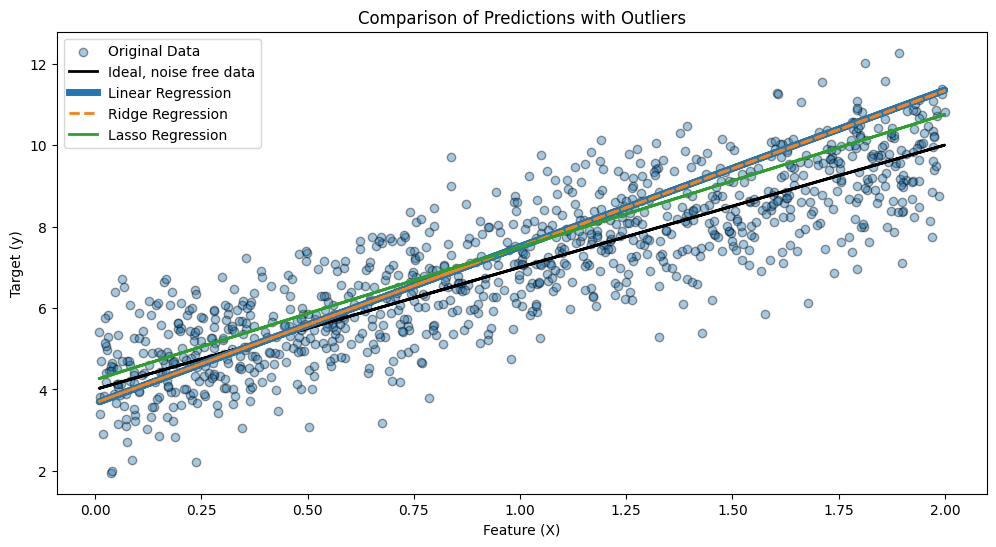

In [9]:
plt.figure(figsize=(12, 6))

# Scatter plot of the original data with outliers
plt.scatter(X, y, alpha=0.4,ec='k', label='Original Data')

# Plot the ideal regression line (noise free data)
plt.plot(X, y_ideal,  linewidth=2, color='k',label='Ideal, noise free data')

# Plot predictions from the simple linear regression model
plt.plot(X, y_outlier_pred_lin,  linewidth=5, label='Linear Regression')

# Plot predictions from the ridge regression model
plt.plot(X, y_outlier_pred_ridge, linestyle='--', linewidth=2, label='Ridge Regression')

# Plot predictions from the lasso regression model
plt.plot(X, y_outlier_pred_lasso,  linewidth=2, label='Lasso Regression')

plt.xlabel('Feature (X)')
plt.ylabel('Target (y)')
plt.title('Comparison of Predictions with Outliers')
plt.legend()
plt.show()

Here all three models were trained on the data with the 5 outliers. The plot shows only the normal points so you can see how far each fitted line drifts from the truth (black line).

Conclusion
The outliers tilted linear regression and Ridge clearly upward. Lasso stayed closer to the ideal line, but for a different reason than robustness.

Reading the lines from the plot:

Model	At X = 0	At X = 2	Slope (approx.)
Ideal (true)	4.0	10.0	3.0
Linear regression	~3.7	~11.35	~3.8
Ridge	~3.7	~11.35	~3.8 (same as linear)
Lasso	~4.25	~10.7	~3.2
Linear regression was pulled by the outliers. The 5 extreme points at high X tilted the line upward: the slope rose from 3 to about 3.8 (about 27% too steep). The line pivots: it predicts too high on the right (about +1.35 at X = 2) and slightly too low on the left (about −0.3 at X = 0).
Ridge made no difference. Its line lies exactly on top of linear regression. With about 1,000 points and a small alpha, the L2 penalty barely affects the coefficient, and Ridge still minimizes squared error, so the outliers pull it just as hard. This confirms that Ridge doesn't protect against outliers.
Lasso came out closest to the truth. Its slope is about 3.2, much closer to 3. That's better than I predicted last time, when I expected it to behave like the others. The reason matters, though: Lasso's L1 penalty shrinks the coefficient toward zero, so it pulls the slope down and compensates with a higher intercept (about 4.25). Here that shrinkage happens to cancel out most of the upward pull from the outliers.
Lasso's good result is partly a coincidence. If the outliers pulled the slope down, or if alpha were larger, Lasso would shrink the slope even more and could end up further from the truth. It doesn't recognize outliers; it just shrinks everything.

In [10]:
from sklearn.datasets import make_regression

X, y, ideal_coef = make_regression(n_samples=100, n_features=100, n_informative=10, noise=10, random_state=42, coef=True)

# Get the ideal predictions based on the informative coefficients used in the regression model
ideal_predictions = X @ ideal_coef

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test, ideal_train, ideal_test = train_test_split(X, y, ideal_predictions, test_size=0.3, random_state=42)

In [11]:
lasso = Lasso(alpha=0.1)
ridge = Ridge(alpha=1.0)
linear = LinearRegression()

# Fit the models
lasso.fit(X_train, y_train)
ridge.fit(X_train, y_train)
linear.fit(X_train, y_train)

# Predict on the test set
y_pred_linear = linear.predict(X_test)
y_pred_ridge = ridge.predict(X_test)
y_pred_lasso = lasso.predict(X_test)

In [12]:
regression_results(y_test, y_pred_linear, 'Ordinary')
regression_results(y_test, y_pred_ridge, 'Ridge')
regression_results(y_test, y_pred_lasso, 'Lasso')

Evaluation metrics for Ordinary Linear Regression
explained_variance:  0.4354
r2:  0.4018
MAE:  77.7353
MSE:  9844.2714
RMSE:  99.2183

Evaluation metrics for Ridge Linear Regression
explained_variance:  0.4446
r2:  0.4079
MAE:  76.9622
MSE:  9744.4693
RMSE:  98.7141

Evaluation metrics for Lasso Linear Regression
explained_variance:  0.9815
r2:  0.9815
MAE:  13.8855
MSE:  304.644
RMSE:  17.4541



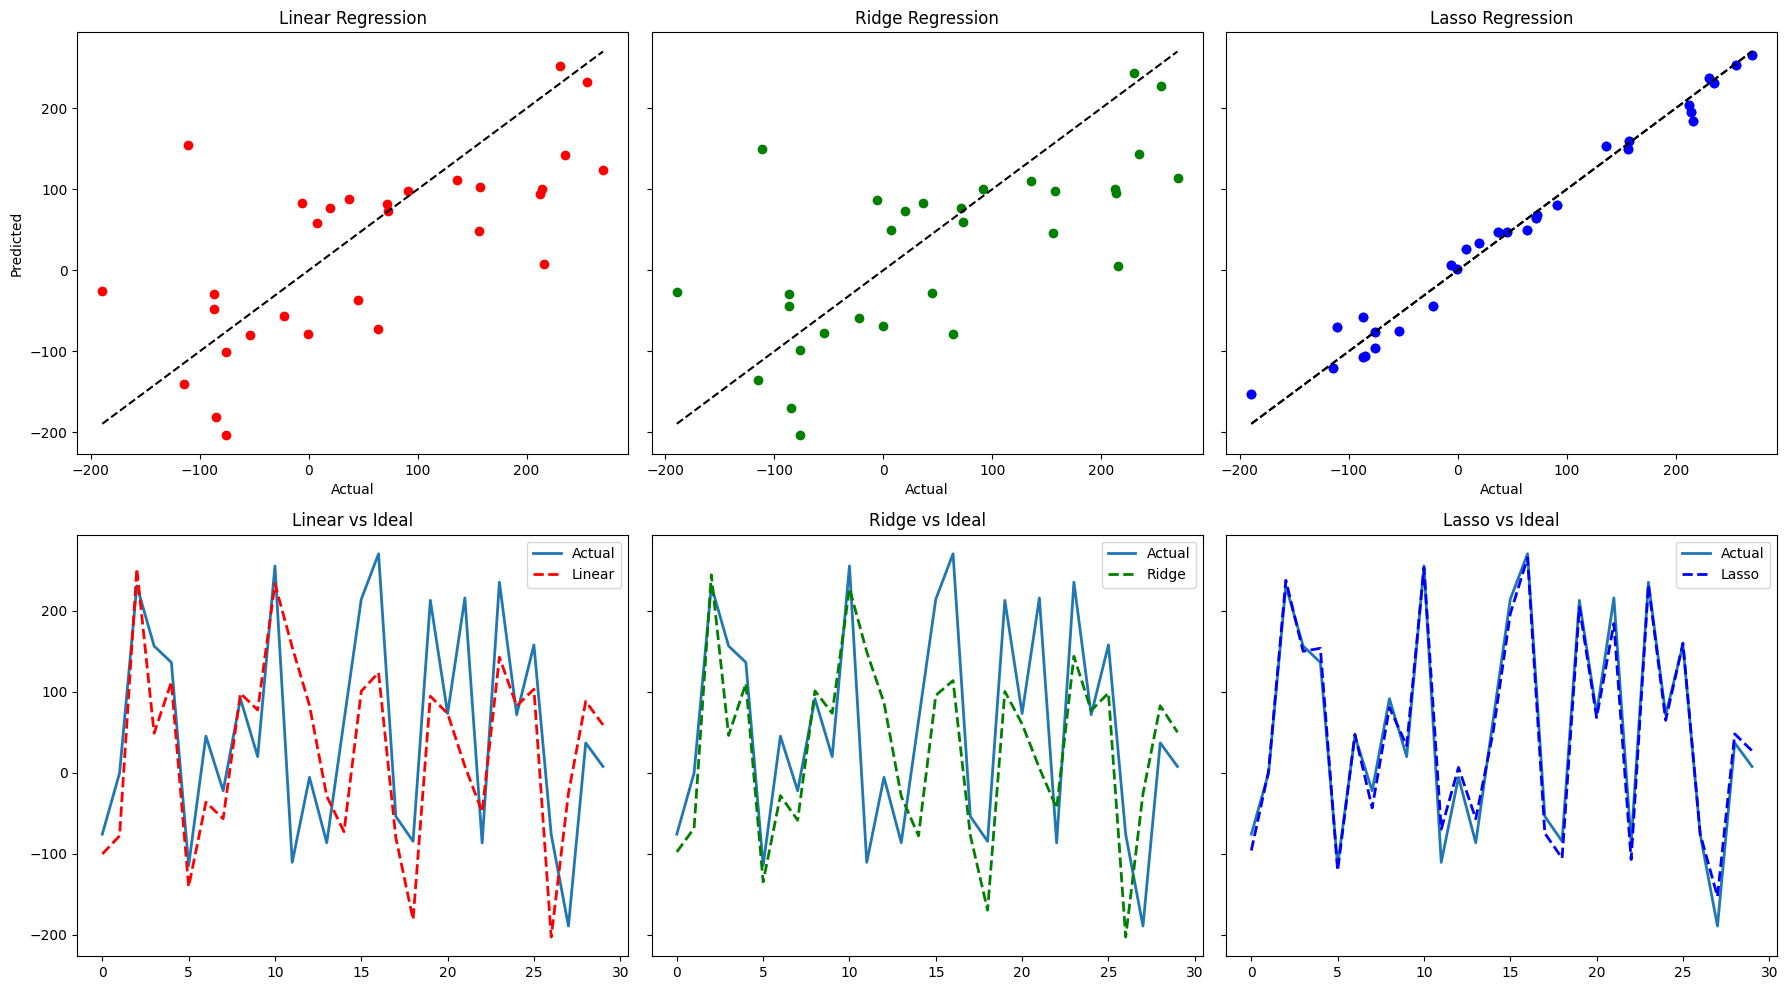

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=True)

axes[0,0].scatter(y_test, y_pred_linear, color="red", label="Linear")
axes[0,0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0,0].set_title("Linear Regression")
axes[0,0].set_xlabel("Actual",)
axes[0,0].set_ylabel("Predicted",)

axes[0,2].scatter(y_test, y_pred_lasso, color="blue", label="Lasso")
axes[0,2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0,2].set_title("Lasso Regression",)
axes[0,2].set_xlabel("Actual",)

axes[0,1].scatter(y_test, y_pred_ridge, color="green", label="Ridge")
axes[0,1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0,1].set_title("Ridge Regression",)
axes[0,1].set_xlabel("Actual",)

axes[0,2].scatter(y_test, y_pred_lasso, color="blue", label="Lasso")
axes[0,2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
axes[0,2].set_title("Lasso Regression",)
axes[0,2].set_xlabel("Actual",)


# Line plots for predictions compared to actual and ideal predictions
axes[1,0].plot(y_test, label="Actual", lw=2)
axes[1,0].plot(y_pred_linear, '--', lw=2, color='red', label="Linear")
axes[1,0].set_title("Linear vs Ideal",)
axes[1,0].legend()
 
axes[1,1].plot(y_test, label="Actual", lw=2)
# axes[1,1].plot(ideal_test, '--', label="Ideal", lw=2, color="purple")
axes[1,1].plot(y_pred_ridge, '--', lw=2, color='green', label="Ridge")
axes[1,1].set_title("Ridge vs Ideal",)
axes[1,1].legend()
 
axes[1,2].plot(y_test, label="Actual", lw=2)
axes[1,2].plot(y_pred_lasso, '--', lw=2, color='blue', label="Lasso")
axes[1,2].set_title("Lasso vs Ideal",)
axes[1,2].legend()
 
plt.tight_layout()
plt.show()

Lasso predicts almost perfectly, while linear regression and Ridge fail on the test data.

Linear regression overfits badly.

Top-left: the points scatter widely around the diagonal, with errors of 100–200 units. For example, actual ≈ −110 is predicted at +155, and actual ≈ 215 is predicted at about 5.
Bottom-left: the red line often goes the opposite way from the blue one, as at samples 11, 15–16 and 19–21.
With about as many features as training samples (or more), ordinary least squares can fit the training data perfectly, noise included. It gives weight to the ~90 useless features, so its predictions on new data are mostly noise.

Ridge is almost identical to linear regression. Its points and line are nearly copies of the linear ones. The L2 penalty shrinks all coefficients a little but keeps every feature, so the irrelevant ones still add noise. Its alpha was probably too small to make a visible difference.

Lasso almost matches the actual values.

Top-right: the points lie tightly on the diagonal across the whole range (−190 to 270).
Bottom-right: the dashed line follows the actual values at almost every sample, with only small misses (for example around samples 11, 18, 22 and 27).
The L1 penalty sets the coefficients of irrelevant features exactly to zero. Lasso automatically keeps only the features that matter and drops the noise.

Why this happens
Linear	Ridge (L2)	Lasso (L1)
Uses irrelevant features	Yes, fully	Yes, slightly shrunk	No, sets them to 0
Behaviour with many features and few samples	Overfits	Overfits (small alpha)	Selects the right features
This is Lasso's real strength: feature selection in sparse problems (many features, few of them important). In the outlier experiment its advantage was partly a coincidence. Here it's exactly what Lasso is designed for.

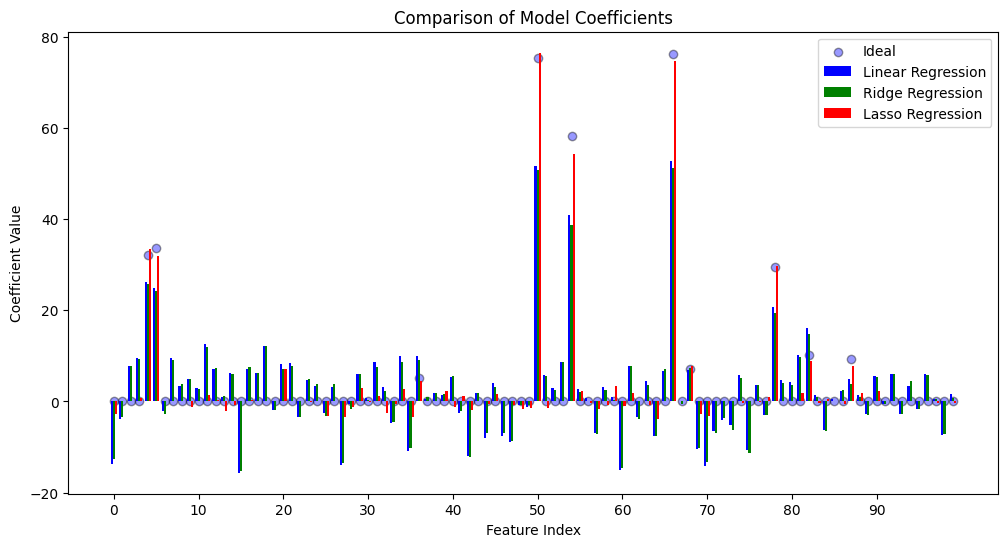

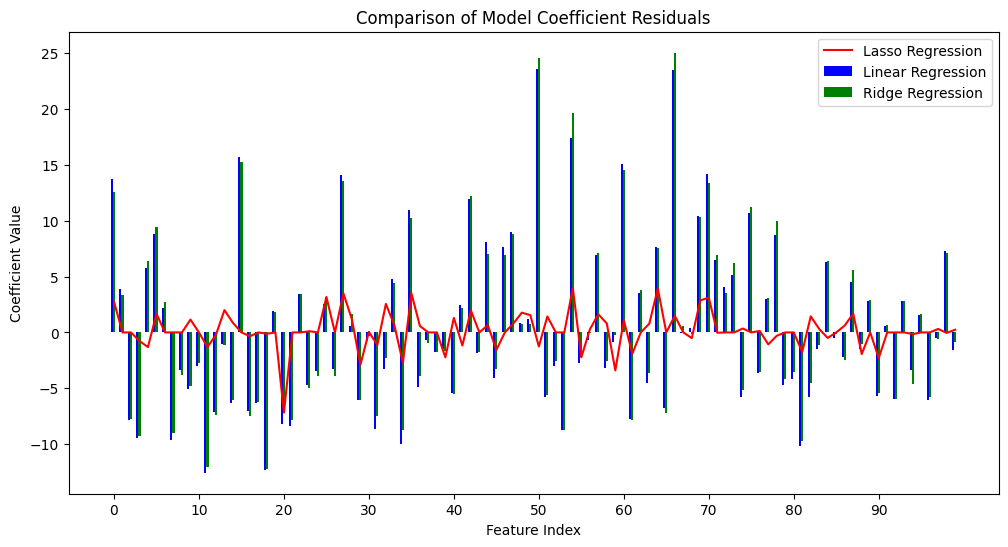

In [14]:
# Model coefficients
linear_coeff = linear.coef_
ridge_coeff = ridge.coef_
lasso_coeff = lasso.coef_


# Plot the coefficients
x_axis = np.arange(len(linear_coeff))
x_labels = np.arange(min(x_axis),max(x_axis),10)
plt.figure(figsize=(12, 6))

plt.scatter(x_axis, ideal_coef,  label='Ideal', color='blue', ec='k', alpha=0.4)
plt.bar(x_axis - 0.25, linear_coeff, width=0.25, label='Linear Regression', color='blue')
plt.bar(x_axis, ridge_coeff, width=0.25, label='Ridge Regression', color='green')
plt.bar(x_axis + 0.25, lasso_coeff, width=0.25, label='Lasso Regression', color='red')

plt.xlabel('Feature Index')
plt.ylabel('Coefficient Value')
plt.title('Comparison of Model Coefficients')
plt.xticks(x_labels)
plt.legend()
plt.show()


# Plot the coefficient residuals
x_axis = np.arange(len(linear_coeff))

plt.figure(figsize=(12, 6))

plt.bar(x_axis - 0.25, ideal_coef - linear_coeff, width=0.25, label='Linear Regression', color='blue')
plt.bar(x_axis, ideal_coef - ridge_coeff, width=0.25, label='Ridge Regression', color='green')
# plt.bar(x_axis + 0.25, ideal_coef - lasso_coeff, width=0.25, label='Lasso Regression', color='red')
plt.plot(x_axis, ideal_coef - lasso_coeff, label='Lasso Regression', color='red')

plt.xlabel('Feature Index')
plt.ylabel('Coefficient Value')
plt.title('Comparison of Model Coefficient Residuals')
plt.xticks(x_labels)
plt.legend()
plt.show()

Only 10 of the 100 features truly matter. Lasso found them and set almost everything else to zero, while linear regression and Ridge spread weight over all 100 features.

The true model is sparse. The ideal coefficients are zero for 90 features. Only these 10 are non-zero:

Feature	True coefficient (approx.)
66	~76
50	~75
54	~58
5	~33.5
4	~32
78	~29.5
82	~10
87	~9
68	~7
36	~5
That matches n_informative=10.

Lasso (red) recovered the true structure.

Its large bars reach almost the exact height of the purple dots: about 76 at feature 50, 75 at 66, 32–33 at features 4–5, and 29 at 78. Feature 54 is a bit low (about 54 vs 58).
For the small true coefficients (68, 82, 87) it also gets close.
For the 90 irrelevant features, its coefficients are zero or almost zero. There are only a few small false positives, such as feature 20 (about 7) and small negative values around 13, 33 and 35.
Linear regression (blue) and Ridge (green) underestimate the important features. Their bars for the big features are clearly too low:

50 and 66: about 51–52 vs 75–76
54: about 40 vs 58
78: about 20 vs 29.5
They capture only about two thirds of the real effect.

They give weight to features that don't matter. For irrelevant features they assign coefficients of ±5 to ±15: for example about −13 at feature 0, −15 at 15, 12 at 18, −14 at 27, −15 at 60 and −13 at 70. These are noise fitted as if it were signal, which caused the poor predictions in the previous plot.

Ridge ≈ linear. Green and blue are almost identical everywhere. Ridge's L2 penalty shrank the coefficients only slightly and never sets one to zero.

Why
With about as many features as samples, linear regression can explain the noise by combining many features, so the weight is divided across many coefficients instead of concentrated on the 10 real ones.
Lasso's L1 penalty costs the same for every unit of any coefficient. It's cheaper to keep a few large coefficients than many small ones, so the irrelevant ones go exactly to zero.
Takeaway